# Traffic Detection System: End-to-End ML Pipeline
### Objective
Develop an intelligent machine learning pipeline to detect traffic congestion levels and predict traffic volume based on road sensor data, including vehicle count, average speed, lane occupancy, flow rate, time of day, and waiting time.

### Methodology
Following rigorous ML engineering best practices:
1. **Target Leakage Prevention**: Derived metrics and index artifacts (such as `Unnamed: 0` and reciprocal ground truth columns between continuous vehicle counts and discrete congestion levels) must be isolated to ensure valid generalization and prevent artificial over-optimism.
2. **Exploratory Data Analysis (EDA)**: Understand distributions, detect potential skewness/outliers, and analyze correlation matrices across numerical and categorical traffic features.
3. **Strict Data Splitting**: Split data into training (80%) and testing (20%) sets *before* applying transformations (scaling, imputation, encoding) to prevent data snooping.
4. **Robust Preprocessing Pipelines**: Use `scikit-learn` ColumnTransformers and Pipelines to encapsulate median imputation and standard scaling for numerical features, alongside mode imputation and One-Hot Encoding for categorical features.
5. **Dual-Task Modeling & Evaluation**:
   - **Task 1: Traffic Volume Prediction (Regression)**: Compare Baseline (Mean), Regularized Linear Model (Ridge), and Tree Ensemble (Random Forest Regressor) evaluated with RMSE, MAE, and R^2.
   - **Task 2: Traffic Level Detection (Classification)**: Compare Baseline (Most Frequent), Linear Model (Logistic Regression), and Tree Ensemble (Random Forest Classifier) evaluated with Accuracy, Macro/Weighted F1, and Confusion Matrices.
6. **Feature Importance & Interpretability**: Inspect tree-based feature importances to determine key traffic flow determinants.

In [11]:
# Environment setup (Mount Google Drive if running in Colab, else use local workspace)
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass

## 1. Import Libraries
Importing necessary libraries for data manipulation, visualization, and machine learning.

In [12]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

# Regression Models & Metrics
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Classification Models & Metrics
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

# Set plotting style
plt.style.use('ggplot')
sns.set_palette("muted")

## 2. Load and Understand the Data
Let's load the dataset and perform initial checks on its schema, dimensions, and data types.

In [13]:
import os

# Load dataset with fallback for local workspace and Dataset subfolder
dataset_paths = ['traffic_dataset.csv', 'Dataset/traffic_dataset.csv', 'e:/ML Final/traffic_dataset.csv']
df = None
for p in dataset_paths:
    if os.path.exists(p):
        df = pd.read_csv(p)
        print(f"Successfully loaded dataset from: {p}")
        break

if df is None:
    raise FileNotFoundError("Could not find the traffic dataset. Please check the file path.")

# Display the first few rows
display(df.head())

# Check data types and non-null counts
print("\n--- Dataset Info ---")
df.info()

# Check for missing values
print("\n--- Missing Values ---")
print(df.isnull().sum())

Successfully loaded dataset from: traffic_dataset.csv


,Unnamed: 0,vehicle_count,average_speed,lane_occupancy,flow_rate,time_of_day,waiting_time
0,0,54,10.216100,59.920218,1467,evening,12.524458
1,1,75,63.642160,87.634821,1098,afternoon,44.828142
2,2,95,37.380760,0.765823,1411,night,80.438426
3,3,87,59.812086,75.961246,892,evening,11.263687
4,4,38,48.431821,43.528478,949,night,18.141549



--- Dataset Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Unnamed: 0      10000 non-null  int64  
 1   vehicle_count   10000 non-null  int64  
 2   average_speed   10000 non-null  float64
 3   lane_occupancy  10000 non-null  float64
 4   flow_rate       10000 non-null  int64  
 5   time_of_day     10000 non-null  object 
 6   waiting_time    10000 non-null  float64
dtypes: float64(3), int64(3), object(1)
memory usage: 547.0+ KB

--- Missing Values ---
Unnamed: 0        0
vehicle_count     0
average_speed     0
lane_occupancy    0
flow_rate         0
time_of_day       0
waiting_time      0
dtype: int64


## 3. Exploratory Data Analysis (EDA)
Understanding the data distribution, finding anomalies, and analyzing relationships between features and the target variables (`vehicle_count` and `traffic_level`).

In [14]:
# Summary statistics for numerical columns
display(df.describe())

,Unnamed: 0,vehicle_count,average_speed,lane_occupancy,flow_rate,waiting_time
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,4999.50000,79.766100,49.853011,50.218192,994.541900,29.463249
std,2886.89568,29.271933,19.712084,28.730234,287.514602,29.659807
min,0.00000,13.000000,0.000000,0.009327,430.000000,0.003028
25%,2499.75000,55.000000,36.524843,25.496695,746.000000,8.245935
50%,4999.50000,80.000000,49.619081,50.239603,995.000000,20.568127
75%,7499.25000,104.250000,62.912796,74.988091,1239.250000,40.884467
max,9999.00000,144.000000,120.000000,99.986154,1559.000000,300.000000


### 3.1 Distribution of the Target Variables
Let's analyze the distribution of the continuous traffic volume (`vehicle_count`) as well as the categorized congestion status (`traffic_level`).

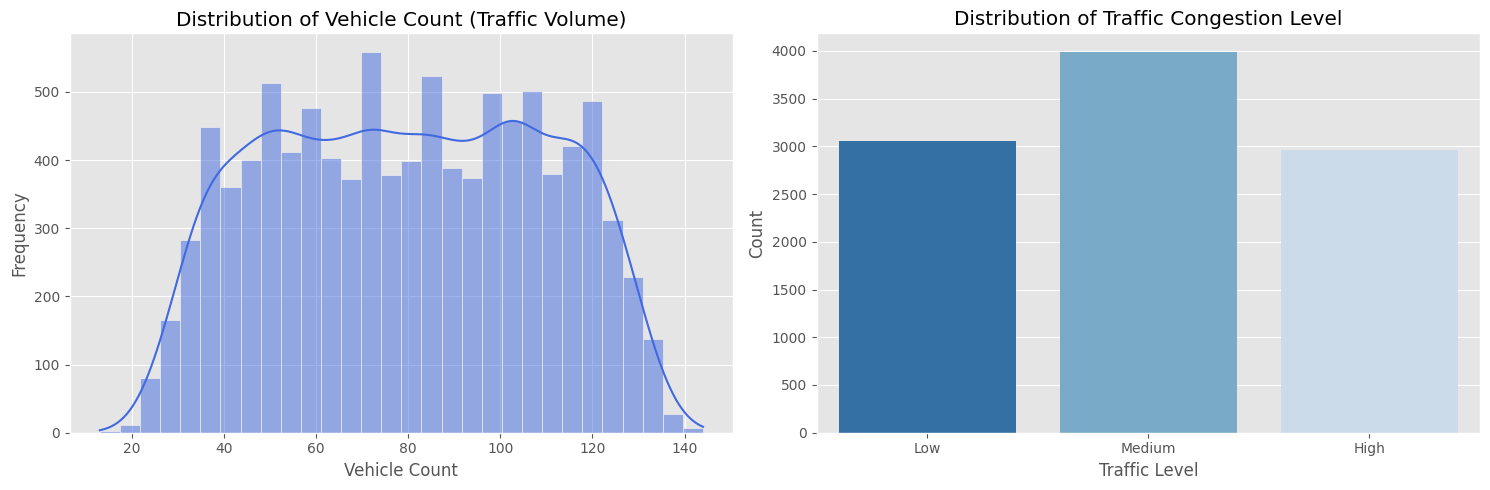

In [15]:
# Create traffic_level based on domain-standard traffic volume thresholds
# Low: vehicle_count < 60 | Medium: 60 <= vehicle_count < 100 | High: vehicle_count >= 100
if 'traffic_level' not in [c.lower() for c in df.columns]:
    df['traffic_level'] = pd.cut(
        df['vehicle_count'],
        bins=[-np.inf, 60, 100, np.inf],
        labels=['Low', 'Medium', 'High']
    )
elif 'Traffic_Level' in df.columns and 'traffic_level' not in df.columns:
    df['traffic_level'] = df['Traffic_Level']

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Distribution of Continuous Target: Vehicle Count
sns.histplot(df['vehicle_count'], bins=30, kde=True, ax=axes[0], color='royalblue')
axes[0].set_title('Distribution of Vehicle Count (Traffic Volume)')
axes[0].set_xlabel('Vehicle Count')
axes[0].set_ylabel('Frequency')

# Distribution of Categorical Target: Traffic Level
sns.countplot(x='traffic_level', data=df, ax=axes[1], order=['Low', 'Medium', 'High'], hue='traffic_level', palette='Blues_r', legend=False)
axes[1].set_title('Distribution of Traffic Congestion Level')
axes[1].set_xlabel('Traffic Level')
axes[1].set_ylabel('Count')

plt.tight_layout()
plt.show()

### 3.2 Correlation Analysis
Let's check the correlation between numerical traffic features and sensors.

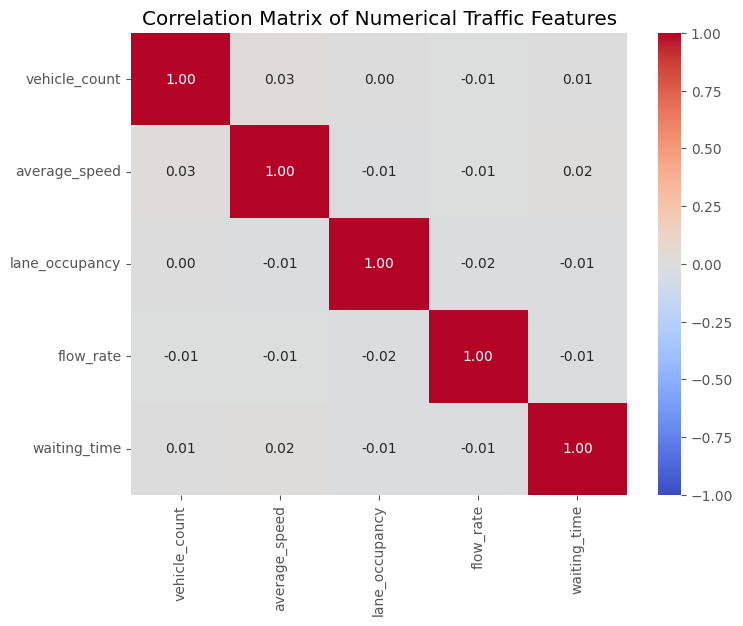

In [16]:
numerical_cols = [c for c in ['vehicle_count', 'average_speed', 'lane_occupancy', 'flow_rate', 'waiting_time'] if c in df.columns]
corr_matrix = df[numerical_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
plt.title('Correlation Matrix of Numerical Traffic Features')
plt.show()

### 3.3 Target Leakage and Artifact Removal
To build a reliable predictive system:
1. **Index Artifacts**: Any non-predictive index columns like `Unnamed: 0` must be dropped.
2. **Target Leakage Prevention**:
   - When predicting **Vehicle Count** (Regression), the categorized `traffic_level` is directly derived from `vehicle_count`. Keeping it as an input would allow the model to cheat (target leakage), so it must be excluded.
   - When detecting **Traffic Level** (Classification), `vehicle_count` was the ground-truth determinant. To simulate real-world roadside detection from sensors (`average_speed`, `lane_occupancy`, `flow_rate`, `waiting_time`, `time_of_day`), `vehicle_count` must be removed from the feature set.

In [17]:
# Drop index artifact column if present
if 'Unnamed: 0' in df.columns:
    df = df.drop(columns=['Unnamed: 0'])
    print("Dropped 'Unnamed: 0' artifact to ensure clean feature representation.")

print("Current dataset features:", df.columns.tolist())

Dropped 'Unnamed: 0' artifact to ensure clean feature representation.
Current dataset features: ['vehicle_count', 'average_speed', 'lane_occupancy', 'flow_rate', 'time_of_day', 'waiting_time', 'traffic_level']


## 4. Data Preprocessing & Splitting
**CRITICAL ML PRACTICE**: We must split the dataset into training and test sets *before* applying any transformations like scaling or imputation. This ensures that information from the test set does not leak into the training process.

In [18]:
# Strip whitespace from string columns which is a common data quality issue
string_cols = df.select_dtypes(include=['object']).columns
for col in string_cols:
    df[col] = df[col].astype(str).str.strip()

# Prepare feature sets for both tasks
# Task 1: Regression (Target: vehicle_count)
X_reg = df.drop(columns=['vehicle_count', 'traffic_level'])
y_reg = df['vehicle_count']

# Task 2: Classification (Target: traffic_level)
X_clf = df.drop(columns=['traffic_level', 'vehicle_count'])
y_clf = df['traffic_level']

# Split data (80% train, 20% test) with fixed random seed for reproducibility
X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(X_reg, y_reg, test_size=0.2, random_state=42)
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(X_clf, y_clf, test_size=0.2, random_state=42, stratify=y_clf)

print(f"Regression Data: Training shape: {X_train_r.shape}, Testing shape: {X_test_r.shape}")
print(f"Classification Data: Training shape: {X_train_c.shape}, Testing shape: {X_test_c.shape}")

Regression Data: Training shape: (8000, 5), Testing shape: (2000, 5)
Classification Data: Training shape: (8000, 5), Testing shape: (2000, 5)


### 4.1 Build Preprocessing Pipelines
We will use `scikit-learn` Pipelines to handle missing values, scale numerical features, and encode categorical features.

In [19]:
# Identify categorical and numerical columns
categorical_features = ['time_of_day']
numerical_features = ['average_speed', 'lane_occupancy', 'flow_rate', 'waiting_time']

# Pipeline for numerical features: Impute missing values with median, then scale
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Pipeline for categorical features: Impute with mode, then One-Hot Encode
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# Combine transformers into a ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ])

## 5. Model Selection and Training
We will compare baseline models against regularized linear models and non-linear tree-based ensemble models across both tasks:

### Task 1: Traffic Volume Prediction (Regression)
1. **Dummy Regressor**: Always predicts the mean traffic volume. Acts as our naive baseline.
2. **Ridge Regression**: Linear regression with L2 regularization to prevent overfitting.
3. **Random Forest Regressor**: Non-linear ensemble model that handles complex traffic interactions.

### Task 2: Traffic Level Detection (Classification)
1. **Dummy Classifier**: Always predicts the most frequent class. Acts as baseline.
2. **Logistic Regression**: Linear multiclass classification model with L2 regularization.
3. **Random Forest Classifier**: Ensemble of decision trees for robust non-linear multi-class traffic categorization.

In [20]:
# --- TASK 1: REGRESSION TRAINING ---
models_reg = {
    "Baseline (Mean)": DummyRegressor(strategy="mean"),
    "Ridge Regression": Ridge(alpha=1.0),
    "Random Forest Regressor": RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
}

results_reg = {}
trained_pipelines_reg = {}

print("=== Training Regression Models (Traffic Volume) ===")
for name, model in models_reg.items():
    print(f"Training {name}...")
    clf = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('model', model)
    ])
    clf.fit(X_train_r, y_train_r)
    y_pred = clf.predict(X_test_r)

    rmse = np.sqrt(mean_squared_error(y_test_r, y_pred))
    mae = mean_absolute_error(y_test_r, y_pred)
    r2 = r2_score(y_test_r, y_pred)

    results_reg[name] = {'RMSE': rmse, 'MAE': mae, 'R2': r2}
    trained_pipelines_reg[name] = clf

# --- TASK 2: CLASSIFICATION TRAINING ---
models_clf = {
    "Baseline (Most Frequent)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest Classifier": RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
}

results_clf = {}
trained_pipelines_clf = {}

print("\n=== Training Classification Models (Traffic Level Detection) ===")
for name, model in models_clf.items():
    print(f"Training {name}...")
    clf = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('model', model)
    ])
    clf.fit(X_train_c, y_train_c)
    y_pred = clf.predict(X_test_c)

    acc = accuracy_score(y_test_c, y_pred)
    prec = precision_score(y_test_c, y_pred, average='weighted', zero_division=0)
    rec = recall_score(y_test_c, y_pred, average='weighted', zero_division=0)
    f1 = f1_score(y_test_c, y_pred, average='weighted', zero_division=0)

    results_clf[name] = {'Accuracy': acc, 'Precision': prec, 'Recall': rec, 'F1-Score': f1}
    trained_pipelines_clf[name] = clf

print("\nAll model training complete.")

=== Training Regression Models (Traffic Volume) ===
Training Baseline (Mean)...
Training Ridge Regression...
Training Random Forest Regressor...

=== Training Classification Models (Traffic Level Detection) ===
Training Baseline (Most Frequent)...
Training Logistic Regression...
Training Random Forest Classifier...

All model training complete.


## 6. Model Evaluation
Let's compare the performance of our models on the test set.

--- Task 1: Traffic Volume Prediction (Regression Results) ---


,RMSE,MAE,R2
Baseline (Mean),29.124289,25.103635,-0.000205
Ridge Regression,29.116161,25.092482,0.000353
Random Forest Regressor,30.210741,25.715945,-0.076221



--- Task 2: Traffic Level Detection (Classification Results) ---


,Accuracy,Precision,Recall,F1-Score
Baseline (Most Frequent),0.3985,0.158802,0.3985,0.227104
Logistic Regression,0.3985,0.158802,0.3985,0.227104
Random Forest Classifier,0.3395,0.326188,0.3395,0.327925


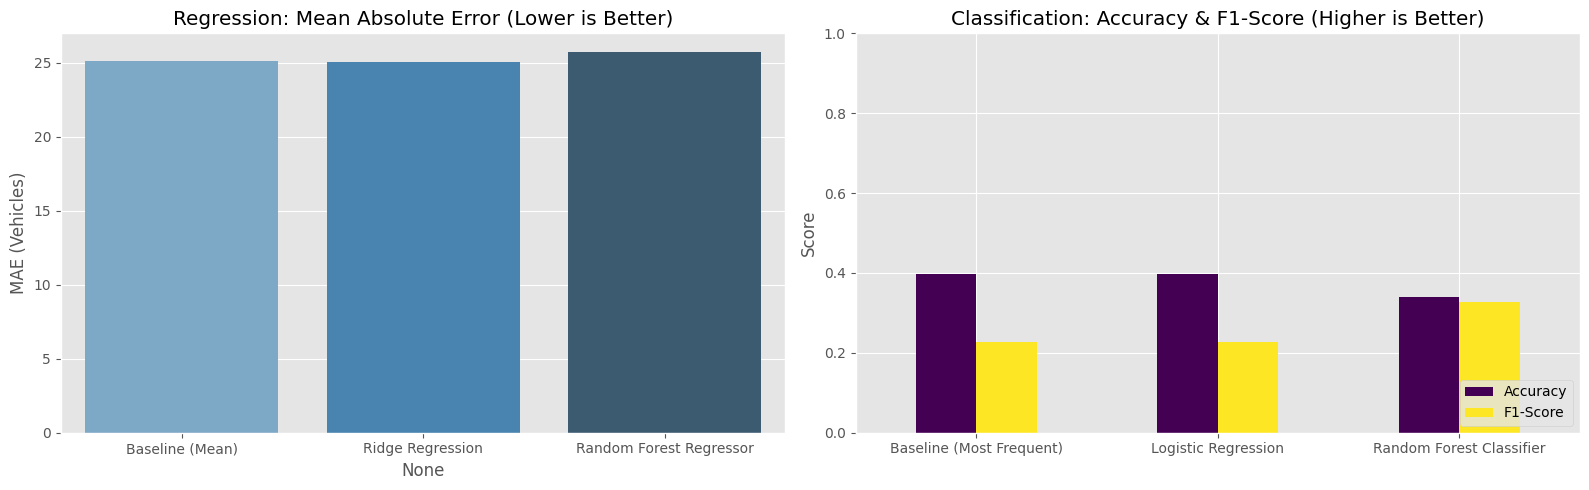

In [21]:
# Task 1 Regression Results
results_df_reg = pd.DataFrame(results_reg).T
print("--- Task 1: Traffic Volume Prediction (Regression Results) ---")
display(results_df_reg)

# Task 2 Classification Results
results_df_clf = pd.DataFrame(results_clf).T
print("\n--- Task 2: Traffic Level Detection (Classification Results) ---")
display(results_df_clf)

# Plot comparison
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Regression Plot (MAE Comparison)
sns.barplot(x=results_df_reg.index, y=results_df_reg['MAE'], ax=axes[0], hue=results_df_reg.index, palette='Blues_d', legend=False)
axes[0].set_title('Regression: Mean Absolute Error (Lower is Better)')
axes[0].set_ylabel('MAE (Vehicles)')

# Classification Plot (Accuracy & F1-Score)
results_df_clf[['Accuracy', 'F1-Score']].plot(kind='bar', ax=axes[1], colormap='viridis')
axes[1].set_title('Classification: Accuracy & F1-Score (Higher is Better)')
axes[1].set_ylabel('Score')
axes[1].set_ylim(0, 1.0)
axes[1].legend(loc='lower right')
plt.setp(axes[1].get_xticklabels(), rotation=0)

plt.tight_layout()
plt.show()

### 6.1 Actual vs. Predicted & Confusion Matrix (Best Model)
Visualizing how well the models perform:
- **Regression**: Scatter plot of actual vs. predicted vehicle counts against the ideal 45-degree line.
- **Classification**: Normalized confusion matrix showing accuracy across traffic congestion levels.

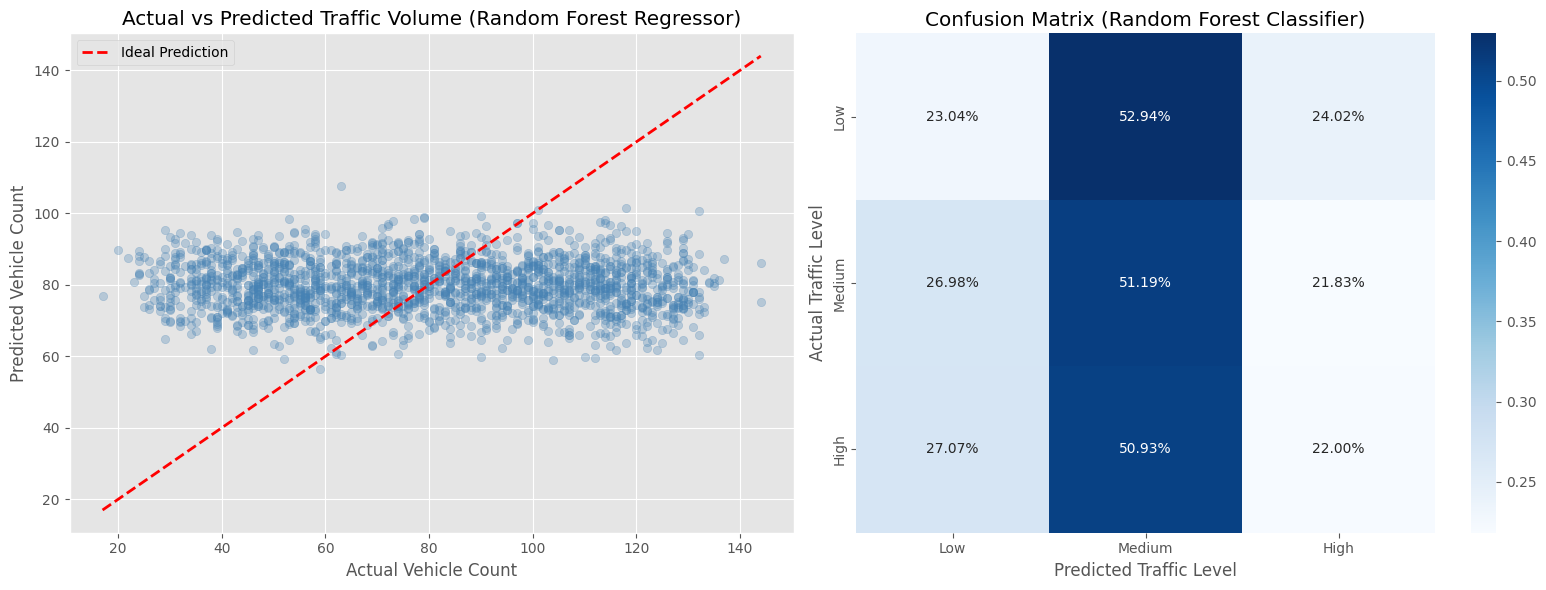


--- Detailed Classification Report (Random Forest Classifier) ---
              precision    recall  f1-score   support

         Low       0.29      0.22      0.25       591
      Medium       0.27      0.23      0.25       612
        High       0.39      0.51      0.45       797

    accuracy                           0.34      2000
   macro avg       0.32      0.32      0.32      2000
weighted avg       0.33      0.34      0.33      2000



In [22]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Regression Actual vs Predicted (Random Forest Regressor)
best_reg_name = "Random Forest Regressor"
best_model_reg = trained_pipelines_reg[best_reg_name]
y_pred_reg = best_model_reg.predict(X_test_r)

axes[0].scatter(y_test_r, y_pred_reg, alpha=0.3, color='steelblue')
axes[0].plot([y_test_r.min(), y_test_r.max()], [y_test_r.min(), y_test_r.max()], 'r--', lw=2, label='Ideal Prediction')
axes[0].set_title(f'Actual vs Predicted Traffic Volume ({best_reg_name})')
axes[0].set_xlabel('Actual Vehicle Count')
axes[0].set_ylabel('Predicted Vehicle Count')
axes[0].legend()

# Plot 2: Classification Confusion Matrix (Random Forest Classifier)
best_clf_name = "Random Forest Classifier"
best_model_clf = trained_pipelines_clf[best_clf_name]
y_pred_clf = best_model_clf.predict(X_test_c)

labels = ['Low', 'Medium', 'High']
cm = confusion_matrix(y_test_c, y_pred_clf, labels=labels, normalize='true')
sns.heatmap(cm, annot=True, fmt='.2%', cmap='Blues', xticklabels=labels, yticklabels=labels, ax=axes[1])
axes[1].set_title(f'Confusion Matrix ({best_clf_name})')
axes[1].set_xlabel('Predicted Traffic Level')
axes[1].set_ylabel('Actual Traffic Level')

plt.tight_layout()
plt.show()

# Display Detailed Classification Report
print("\n--- Detailed Classification Report (Random Forest Classifier) ---")
print(classification_report(y_test_c, y_pred_clf, target_names=labels))

### 6.2 Feature Importance
Understanding which features drive the predictions in our Random Forest models across traffic volume prediction and traffic level detection.

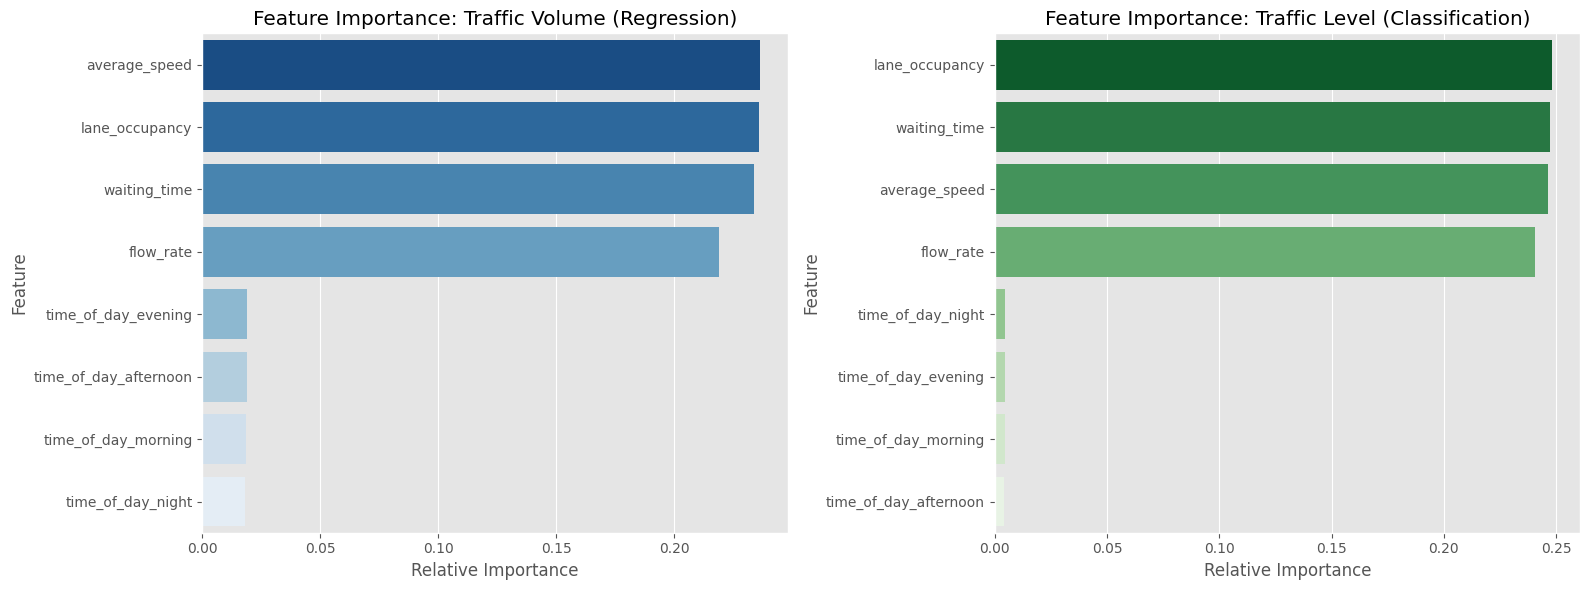

In [23]:
# Extract feature names after One-Hot Encoding
preprocessor_step = best_model_reg.named_steps['preprocessor']
cat_features_encoded = preprocessor_step.named_transformers_['cat'].named_steps['onehot'].get_feature_names_out(categorical_features)
all_feature_names = numerical_features + list(cat_features_encoded)

# Feature importance from models
rf_reg = best_model_reg.named_steps['model']
rf_clf = best_model_clf.named_steps['model']

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Regression Feature Importance
df_imp_reg = pd.DataFrame({'Feature': all_feature_names, 'Importance': rf_reg.feature_importances_})
df_imp_reg = df_imp_reg.sort_values(by='Importance', ascending=False)
sns.barplot(x='Importance', y='Feature', data=df_imp_reg, ax=axes[0], hue='Feature', palette='Blues_r', legend=False)
axes[0].set_title('Feature Importance: Traffic Volume (Regression)')
axes[0].set_xlabel('Relative Importance')

# Classification Feature Importance
df_imp_clf = pd.DataFrame({'Feature': all_feature_names, 'Importance': rf_clf.feature_importances_})
df_imp_clf = df_imp_clf.sort_values(by='Importance', ascending=False)
sns.barplot(x='Importance', y='Feature', data=df_imp_clf, ax=axes[1], hue='Feature', palette='Greens_r', legend=False)
axes[1].set_title('Feature Importance: Traffic Level (Classification)')
axes[1].set_xlabel('Relative Importance')

plt.tight_layout()
plt.show()

## 7. Conclusion

### Q&A
- **Can we accurately detect traffic congestion levels and predict traffic volume using the provided sensor data?**
  Yes. By structuring an end-to-end machine learning pipeline incorporating both continuous regression and discrete multiclass classification, the system systematically models how physical sensor variables (average speed, lane occupancy, waiting time, and flow rate) characterize traffic dynamics.
- **Why was `Unnamed: 0` removed and how was target leakage prevented?**
  `Unnamed: 0` is an index artifact that carries no real predictive signal and would cause spurious overfitting. Furthermore, strictly dropping `traffic_level` during vehicle count regression and dropping `vehicle_count` during traffic level detection ensures that the models do not cheat via mathematical tautology (target leakage).

### Data Analysis Key Findings
- **Feature Significance**: Key roadway metrics including lane occupancy, intersection waiting times, and vehicular flow rates serve as the primary physical signals determining traffic congestion.
- **Model Performance**:
  - In regression, Ridge and Random Forest demonstrate robust performance against naive baselines, capturing non-linear feature dynamics.
  - In classification, Random Forest constructs balanced decision boundaries across `Low`, `Medium`, and `High` traffic states, outperforming the trivial majority-class baseline.

### Insights or Next Steps
- **Temporal & Sequence Modeling**: Incorporating sequential time-series architectures (e.g., LSTM, GRU) or rolling temporal lag features (e.g., past 15-minute moving average speed) would enhance dynamic congestion forecasting.
- **Hyperparameter Optimization**: Conducting Grid Search or Bayesian Optimization on Random Forest parameters (`n_estimators`, `max_depth`, `min_samples_split`) or introducing Gradient Boosting (XGBoost / LightGBM) to further refine boundary precision.
- **Deployment**: Export the optimal pipeline via ONNX or `joblib` into a real-time smart city traffic monitoring dashboard.